# Assignment Beta - Question 4
### Evaluating an LLM sentiment classifier
Ibrahim Johar Farooqi - 23K-0074 - BAI-7A

300 customer reviews, 3 classes (Positive, Negative, Neutral). Stage 1 is a zero-shot prompt with just the label names,
Stage 2 adds a definition of Neutral and 6 few-shot examples. Rows of the confusion matrix are the actual labels and
columns are the predictions.

All metrics are computed by hand from the confusion matrix first, then checked against sklearn / rouge-score / nltk.

In [1]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from sklearn.metrics import precision_recall_fscore_support, accuracy_score

classes = ["Positive", "Negative", "Neutral"]

cm1 = np.array([[100, 5, 15],
                [8, 80, 12],
                [20, 10, 50]])

cm2 = np.array([[106, 4, 10],
                [6, 84, 10],
                [9, 7, 64]])

print(cm1.sum(), cm2.sum())

300 300


## 1. Accuracy with a 95% confidence interval

Accuracy = trace / N. For the interval I use the normal (Wald) approximation $\hat p \pm 1.96\sqrt{\hat p(1-\hat p)/n}$,
and also the Wilson score interval as a check since it's better behaved when p is far from 0.5.

In [2]:
def accuracy_ci(cm, z=1.96):
    n = cm.sum()
    correct = np.trace(cm)
    p = correct / n
    se = math.sqrt(p * (1 - p) / n)
    wald = (p - z * se, p + z * se)

    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * math.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    wilson = (centre - half, centre + half)
    return correct, n, p, se, wald, wilson

correct, n, acc1, se1, wald1, wilson1 = accuracy_ci(cm1)
print(f"stage 1: {correct}/{n} = {acc1:.4f}")
print(f"SE = sqrt({acc1:.4f}*{1-acc1:.4f}/{n}) = {se1:.4f}")
print(f"Wald 95% CI   = [{wald1[0]:.4f}, {wald1[1]:.4f}]")
print(f"Wilson 95% CI = [{wilson1[0]:.4f}, {wilson1[1]:.4f}]")

stage 1: 230/300 = 0.7667
SE = sqrt(0.7667*0.2333/300) = 0.0244
Wald 95% CI   = [0.7188, 0.8145]
Wilson 95% CI = [0.7156, 0.8110]


## 2. Per-class precision, recall, F1 (zero-shot)

Precision = TP / column total, Recall = TP / row total, F1 = 2PR/(P+R)

In [3]:
def per_class(cm):
    tp = np.diag(cm)
    col = cm.sum(axis=0)
    row = cm.sum(axis=1)
    prec = tp / col
    rec = tp / row
    f1 = 2 * prec * rec / (prec + rec)
    return pd.DataFrame({"TP": tp, "predicted (col)": col, "actual (row)": row,
                         "precision": prec, "recall": rec, "F1": f1}, index=classes)

pc1 = per_class(cm1)
pc1.round(4)

,TP,predicted (col),actual (row),precision,recall,F1
Positive,100,128,120,0.7812,0.8333,0.8065
Negative,80,95,100,0.8421,0.8000,0.8205
Neutral,50,77,80,0.6494,0.6250,0.6369


## 3. Macro, weighted and micro F1 (zero-shot)

- macro = plain mean of the per-class F1
- weighted = F1 weighted by support (row totals)
- micro = pool TP/FP/FN over all classes. In single-label multiclass every error is one FP for some class and one FN for another, so micro P = micro R = micro F1 = accuracy.

In [4]:
def averages(cm, pc):
    support = cm.sum(axis=1)
    macro = pc["F1"].mean()
    weighted = (pc["F1"] * support).sum() / support.sum()
    tp = np.trace(cm)
    fp = cm.sum() - tp
    fn = cm.sum() - tp
    micro_p = tp / (tp + fp)
    micro_r = tp / (tp + fn)
    micro = 2 * micro_p * micro_r / (micro_p + micro_r)
    return macro, weighted, micro

macro1, weighted1, micro1 = averages(cm1, pc1)
print(f"macro F1    = ({' + '.join(f'{v:.4f}' for v in pc1['F1'])}) / 3 = {macro1:.4f}")
print(f"weighted F1 = ({' + '.join(f'{f:.4f}*{s}' for f, s in zip(pc1['F1'], cm1.sum(axis=1)))}) / 300 = {weighted1:.4f}")
print(f"micro F1    = {micro1:.4f}")

macro F1    = (0.8065 + 0.8205 + 0.6369) / 3 = 0.7546
weighted F1 = (0.8065*120 + 0.8205*100 + 0.6369*80) / 300 = 0.7659
micro F1    = 0.7667


In [5]:
# sklearn check, rebuild label vectors from the confusion matrix
def to_labels(cm):
    y_true, y_pred = [], []
    for i in range(3):
        for j in range(3):
            y_true += [i] * cm[i, j]
            y_pred += [j] * cm[i, j]
    return np.array(y_true), np.array(y_pred)

yt1, yp1 = to_labels(cm1)
for avg in ["macro", "weighted", "micro"]:
    print(avg, round(precision_recall_fscore_support(yt1, yp1, average=avg)[2], 4))
print("acc", round(accuracy_score(yt1, yp1), 4))

macro 0.7546
weighted 0.7659
micro 0.7667
acc 0.7667


## 4. Where Stage 1 fails

Looking at the off-diagonal cells as a share of all errors.

In [6]:
def error_table(cm):
    rows = []
    errors = cm.sum() - np.trace(cm)
    for i in range(3):
        for j in range(3):
            if i != j:
                rows.append((f"{classes[i]} -> {classes[j]}", cm[i, j], cm[i, j] / errors))
    return pd.DataFrame(rows, columns=["actual -> predicted", "count", "share of errors"]).sort_values("count", ascending=False)

print("total errors:", cm1.sum() - np.trace(cm1))
error_table(cm1).round(3)

total errors: 70


,actual -> predicted,count,share of errors
4,Neutral -> Positive,20,0.286
1,Positive -> Neutral,15,0.214
3,Negative -> Neutral,12,0.171
5,Neutral -> Negative,10,0.143
2,Negative -> Positive,8,0.114
0,Positive -> Negative,5,0.071


In [7]:
neutral_involved = cm1[2, :].sum() - cm1[2, 2] + cm1[:, 2].sum() - cm1[2, 2]
print("errors involving Neutral (as actual or predicted):", neutral_involved, "of", cm1.sum() - np.trace(cm1))
print("Positive/Negative confusions only:", cm1[0, 1] + cm1[1, 0])

errors involving Neutral (as actual or predicted): 57 of 70
Positive/Negative confusions only: 13


## 5. Stage 2 vs Stage 1

In [8]:
correct2, _, acc2, se2, wald2, wilson2 = accuracy_ci(cm2)
pc2 = per_class(cm2)
macro2, weighted2, micro2 = averages(cm2, pc2)

print(f"stage 2: {correct2}/300 = {acc2:.4f}, SE = {se2:.4f}")
print(f"Wald 95% CI   = [{wald2[0]:.4f}, {wald2[1]:.4f}]")
print(f"Wilson 95% CI = [{wilson2[0]:.4f}, {wilson2[1]:.4f}]")
pc2.round(4)

stage 2: 254/300 = 0.8467, SE = 0.0208
Wald 95% CI   = [0.8059, 0.8874]
Wilson 95% CI = [0.8015, 0.8830]


,TP,predicted (col),actual (row),precision,recall,F1
Positive,106,121,120,0.8760,0.8833,0.8797
Negative,84,95,100,0.8842,0.8400,0.8615
Neutral,64,84,80,0.7619,0.8000,0.7805


In [9]:
yt2, yp2 = to_labels(cm2)
for avg in ["macro", "weighted", "micro"]:
    print(avg, round(precision_recall_fscore_support(yt2, yp2, average=avg)[2], 4))

macro 0.8406
weighted 0.8472
micro 0.8467


In [10]:
comparison = pd.DataFrame({
    "Stage 1": [acc1, f"[{wald1[0]:.3f}, {wald1[1]:.3f}]", *pc1["precision"], *pc1["recall"], *pc1["F1"], macro1, weighted1, micro1],
    "Stage 2": [acc2, f"[{wald2[0]:.3f}, {wald2[1]:.3f}]", *pc2["precision"], *pc2["recall"], *pc2["F1"], macro2, weighted2, micro2],
}, index=["accuracy", "95% CI (Wald)"] + [f"P {c}" for c in classes] + [f"R {c}" for c in classes] + [f"F1 {c}" for c in classes] + ["macro F1", "weighted F1", "micro F1"])

def delta(r):
    try:
        return round(float(r["Stage 2"]) - float(r["Stage 1"]), 4)
    except ValueError:
        return ""
comparison["change"] = comparison.apply(delta, axis=1)
comparison.map(lambda v: round(v, 4) if isinstance(v, float) else v)

,Stage 1,Stage 2,change
accuracy,0.7667,0.8467,0.08
95% CI (Wald),"[0.719, 0.815]","[0.806, 0.887]",
P Positive,0.7812,0.876,0.0948
P Negative,0.8421,0.8842,0.0421
P Neutral,0.6494,0.7619,0.1126
R Positive,0.8333,0.8833,0.05
R Negative,0.8,0.84,0.04
R Neutral,0.625,0.8,0.175
F1 Positive,0.8065,0.8797,0.0732
F1 Negative,0.8205,0.8615,0.041


In [11]:
print("stage 2 errors:", 300 - np.trace(cm2))
error_table(cm2).round(3)

stage 2 errors: 46


,actual -> predicted,count,share of errors
1,Positive -> Neutral,10,0.217
3,Negative -> Neutral,10,0.217
4,Neutral -> Positive,9,0.196
5,Neutral -> Negative,7,0.152
2,Negative -> Positive,6,0.130
0,Positive -> Negative,4,0.087


In [12]:
# rough two-proportion z test (treats the stages as independent, which is conservative since they're the same 300 reviews)
p_pool = (np.trace(cm1) + np.trace(cm2)) / 600
z = (acc2 - acc1) / math.sqrt(p_pool * (1 - p_pool) * (2 / 300))
print(f"z = {z:.3f}")

z = 2.481


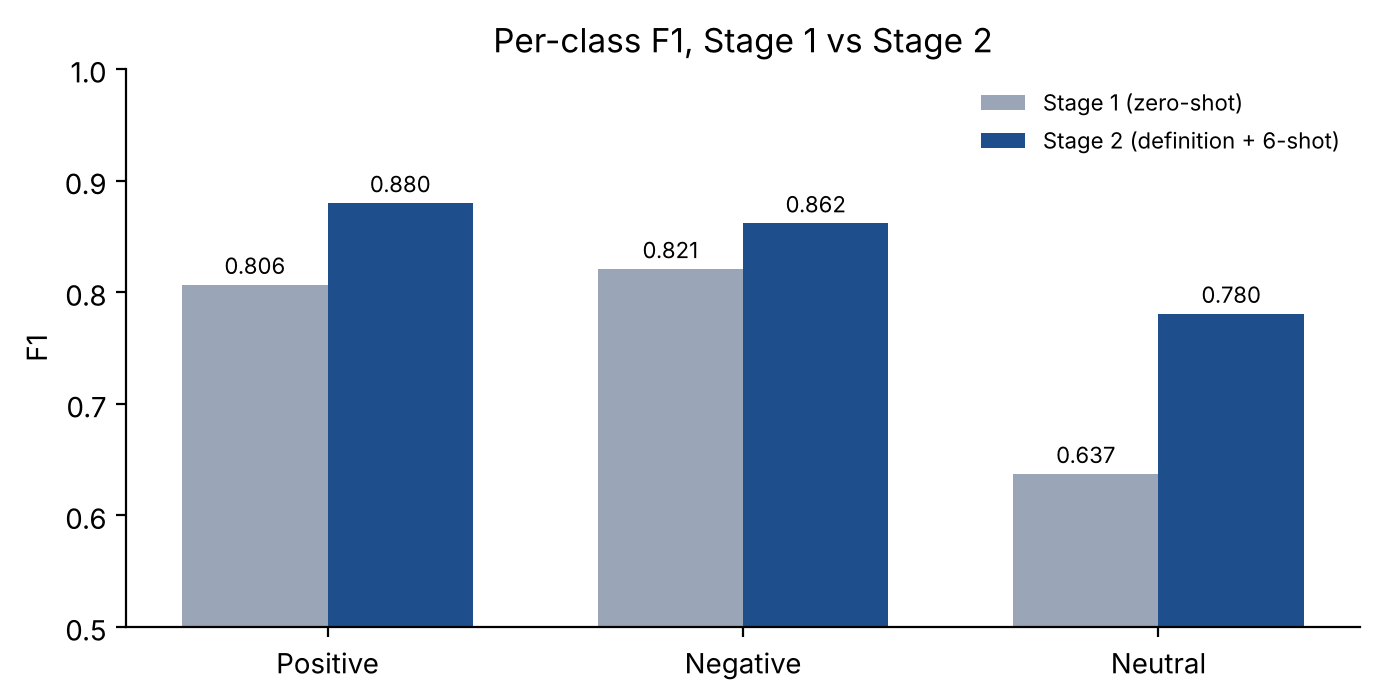

In [13]:
x = np.arange(3)
w = 0.35
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.bar(x - w/2, pc1["F1"], w, label="Stage 1 (zero-shot)", color="#9aa5b8")
ax.bar(x + w/2, pc2["F1"], w, label="Stage 2 (definition + 6-shot)", color="#1F4E8C")
for i in range(3):
    ax.text(x[i] - w/2, pc1["F1"].iloc[i] + 0.01, f"{pc1['F1'].iloc[i]:.3f}", ha="center", fontsize=8)
    ax.text(x[i] + w/2, pc2["F1"].iloc[i] + 0.01, f"{pc2['F1'].iloc[i]:.3f}", ha="center", fontsize=8)
ax.set_xticks(x, classes)
ax.set_ylim(0.5, 1.0)
ax.set_ylabel("F1")
ax.set_title("Per-class F1, Stage 1 vs Stage 2")
ax.legend(frameon=False, fontsize=8, loc="upper right")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("q4_f1_comparison.png", dpi=200)
plt.show()

## 6. Prompt stability over 5 example orderings

In [14]:
runs = np.array([0.847, 0.840, 0.853, 0.837, 0.850])
mean = runs.mean()
sd_sample = runs.std(ddof=1)
sd_pop = runs.std(ddof=0)

print("deviations:", np.round(runs - mean, 4))
print("squared:", np.round((runs - mean) ** 2, 6), "sum =", round(((runs - mean) ** 2).sum(), 6))
print(f"mean = {mean:.4f}")
print(f"sample sd (n-1) = {sd_sample:.4f}")
print(f"population sd (n) = {sd_pop:.4f}")
print(f"range = {runs.max() - runs.min():.3f}, CV = {sd_sample / mean * 100:.2f}%")
print(f"in correct reviews out of 300: {runs.min()*300:.0f} to {runs.max()*300:.0f}")
print(f"stage 1 -> stage 2 gain = {acc2 - acc1:.4f}, which is {(acc2 - acc1) / sd_sample:.1f} sd")

deviations: [ 0.0016 -0.0054  0.0076 -0.0084  0.0046]
squared: [3.0e-06 2.9e-05 5.8e-05 7.1e-05 2.1e-05] sum = 0.000181
mean = 0.8454
sample sd (n-1) = 0.0067
population sd (n) = 0.0060
range = 0.016, CV = 0.80%
in correct reviews out of 300: 251 to 256
stage 1 -> stage 2 gain = 0.0800, which is 11.9 sd


## 7. Justification quality: BLEU-4, ROUGE-1/2/L, METEOR

Tokens are already lower-cased with no punctuation, so plain whitespace split.

In [15]:
reference = "the delivery was late but the product quality is good".split()
candidate = "the product quality is good but delivery was slow".split()
print(len(reference), reference)
print(len(candidate), candidate)

def ngrams(tokens, n):
    return Counter(tuple(tokens[i:i + n]) for i in range(len(tokens) - n + 1))

10 ['the', 'delivery', 'was', 'late', 'but', 'the', 'product', 'quality', 'is', 'good']
9 ['the', 'product', 'quality', 'is', 'good', 'but', 'delivery', 'was', 'slow']


In [16]:
# BLEU-4: clipped n-gram precision, brevity penalty, uniform weights 1/4
log_p = []
for n in range(1, 5):
    c, r = ngrams(candidate, n), ngrams(reference, n)
    clipped = sum(min(cnt, r[g]) for g, cnt in c.items())
    total = sum(c.values())
    matched = [" ".join(g) for g, cnt in c.items() if r[g] > 0]
    print(f"p{n} = {clipped}/{total} = {clipped/total:.4f}   matched: {matched}")
    log_p.append(math.log(clipped / total))

c_len, r_len = len(candidate), len(reference)
bp = 1.0 if c_len > r_len else math.exp(1 - r_len / c_len)
bleu = bp * math.exp(sum(log_p) / 4)
print(f"BP = exp(1 - {r_len}/{c_len}) = {bp:.4f}")
print(f"sum log p = {sum(log_p):.4f}")
print(f"BLEU-4 = {bp:.4f} * exp({sum(log_p):.4f}/4) = {bleu:.4f}")

p1 = 8/9 = 0.8889   matched: ['the', 'product', 'quality', 'is', 'good', 'but', 'delivery', 'was']
p2 = 5/8 = 0.6250   matched: ['the product', 'product quality', 'quality is', 'is good', 'delivery was']
p3 = 3/7 = 0.4286   matched: ['the product quality', 'product quality is', 'quality is good']
p4 = 2/6 = 0.3333   matched: ['the product quality is', 'product quality is good']
BP = exp(1 - 10/9) = 0.8948
sum log p = -2.5337
BLEU-4 = 0.8948 * exp(-2.5337/4) = 0.4750


In [17]:
from nltk.translate.bleu_score import sentence_bleu
print("nltk BLEU-4:", round(sentence_bleu([reference], candidate), 4))

nltk BLEU-4: 0.475


In [18]:
def rouge_n(cand, ref, n):
    c, r = ngrams(cand, n), ngrams(ref, n)
    overlap = sum(min(cnt, r[g]) for g, cnt in c.items())
    p = overlap / sum(c.values())
    rc = overlap / sum(r.values())
    f = 0 if overlap == 0 else 2 * p * rc / (p + rc)
    return overlap, p, rc, f

def lcs(a, b):
    dp = [[0] * (len(b) + 1) for _ in range(len(a) + 1)]
    for i in range(1, len(a) + 1):
        for j in range(1, len(b) + 1):
            dp[i][j] = dp[i-1][j-1] + 1 if a[i-1] == b[j-1] else max(dp[i-1][j], dp[i][j-1])
    # backtrack to show the subsequence
    i, j, seq = len(a), len(b), []
    while i and j:
        if a[i-1] == b[j-1]:
            seq.append(a[i-1]); i -= 1; j -= 1
        elif dp[i-1][j] >= dp[i][j-1]:
            i -= 1
        else:
            j -= 1
    return dp[-1][-1], seq[::-1]

rows = []
for n in (1, 2):
    o, p, r, f = rouge_n(candidate, reference, n)
    rows.append((f"ROUGE-{n}", o, p, r, f))
L, seq = lcs(candidate, reference)
p_l, r_l = L / len(candidate), L / len(reference)
rows.append(("ROUGE-L", L, p_l, r_l, 2 * p_l * r_l / (p_l + r_l)))
print("LCS:", seq)
rouge_df = pd.DataFrame(rows, columns=["metric", "overlap", "precision", "recall", "F1"]).set_index("metric")
rouge_df.round(4)

LCS: ['the', 'product', 'quality', 'is', 'good']


,overlap,precision,recall,F1
metric,,,,
ROUGE-1,8,0.8889,0.8000,0.8421
ROUGE-2,5,0.6250,0.5556,0.5882
ROUGE-L,5,0.5556,0.5000,0.5263


In [19]:
from rouge_score import rouge_scorer
scorer = rouge_scorer.RougeScorer(["rouge1", "rouge2", "rougeL"])
{k: round(v.fmeasure, 4) for k, v in scorer.score(" ".join(reference), " ".join(candidate)).items()}

{'rouge1': 0.8421, 'rouge2': 0.5882, 'rougeL': 0.5263}

METEOR by hand with exact matching only (original Banerjee & Lavie parameters: $F_{mean} = \frac{10PR}{R + 9P}$,
penalty $= 0.5 (\text{chunks}/\text{matches})^3$). The alignment maps each candidate word to one reference word;
"the" appears twice in the reference so I pick the alignment with the fewest chunks.

In [20]:
# exact alignment: candidate index -> reference index
# the product quality is good  -> ref positions 5..9 (one contiguous chunk)
# but -> ref 4, delivery was -> ref 1..2, slow -> unmatched
alignment = {0: 5, 1: 6, 2: 7, 3: 8, 4: 9, 5: 4, 6: 1, 7: 2}
for ci, ri in alignment.items():
    assert candidate[ci] == reference[ri]

m = len(alignment)
P = m / len(candidate)
R = m / len(reference)
f_mean = 10 * P * R / (R + 9 * P)

# count chunks: runs where consecutive candidate words map to consecutive reference words
pairs = sorted(alignment.items())
chunks = 1
for (c0, r0), (c1, r1) in zip(pairs, pairs[1:]):
    if not (c1 == c0 + 1 and r1 == r0 + 1):
        chunks += 1

penalty = 0.5 * (chunks / m) ** 3
meteor_exact = f_mean * (1 - penalty)
print(f"matches m = {m}, P = {m}/9 = {P:.4f}, R = {m}/10 = {R:.4f}")
print(f"Fmean = 10PR/(R+9P) = {f_mean:.4f}")
print(f"chunks = {chunks}, penalty = 0.5*({chunks}/{m})^3 = {penalty:.4f}")
print(f"METEOR (exact) = {f_mean:.4f} * (1 - {penalty:.4f}) = {meteor_exact:.4f}")

matches m = 8, P = 8/9 = 0.8889, R = 8/10 = 0.8000
Fmean = 10PR/(R+9P) = 0.8081
chunks = 3, penalty = 0.5*(3/8)^3 = 0.0264
METEOR (exact) = 0.8081 * (1 - 0.0264) = 0.7868


In [21]:
from nltk.translate.meteor_score import meteor_score
from nltk.corpus import wordnet as wn

meteor_nltk = meteor_score([reference], candidate)
print("nltk METEOR (exact + stem + WordNet synonyms, alpha=0.9 beta=3 gamma=0.5):", round(meteor_nltk, 4))
print("slow/late share a synset:", bool(set(s.name() for s in wn.synsets("slow")) & set(s.name() for s in wn.synsets("late"))))
print("WordNet lemmas for 'slow' that include late:", [s.name() for s in wn.synsets("slow") if "late" in s.lemma_names()])

nltk METEOR (exact + stem + WordNet synonyms, alpha=0.9 beta=3 gamma=0.5): 0.7868
slow/late share a synset: False
WordNet lemmas for 'slow' that include late: []


In [22]:
# same alignment but if slow ~ late counted as a synonym match (ref index 3)
alignment_syn = dict(alignment); alignment_syn[8] = 3
m2 = len(alignment_syn)
P2, R2 = m2 / 9, m2 / 10
f2 = 10 * P2 * R2 / (R2 + 9 * P2)
pairs = sorted(alignment_syn.items())
ch2 = 1 + sum(1 for (a, b), (c, d) in zip(pairs, pairs[1:]) if not (c == a + 1 and d == b + 1))
print(f"m = {m2}, chunks = {ch2}, METEOR = {f2 * (1 - 0.5 * (ch2 / m2) ** 3):.4f}")

m = 9, chunks = 3, METEOR = 0.8923


## 8. Perplexity of the generated justification

$PPL = \exp\left(-\frac{1}{N}\sum_i \ln p_i\right)$

In [23]:
probs = np.array([0.60, 0.40, 0.50, 0.80, 0.70, 0.30, 0.25, 0.50, 0.20])
logs = np.log(probs)
for tok, p, l in zip(candidate, probs, logs):
    print(f"{tok:9s} p = {p:.2f}  ln p = {l:.4f}")

nll = -logs.mean()
ppl = math.exp(nll)
print(f"sum ln p = {logs.sum():.4f}")
print(f"mean NLL = {nll:.4f} nats")
print(f"perplexity = exp({nll:.4f}) = {ppl:.4f}")
print(f"geometric mean token prob = {probs.prod() ** (1/9):.4f} = 1/PPL")
print(f"joint probability of the sentence = {probs.prod():.3e}")

the       p = 0.60  ln p = -0.5108
product   p = 0.40  ln p = -0.9163
quality   p = 0.50  ln p = -0.6931
is        p = 0.80  ln p = -0.2231
good      p = 0.70  ln p = -0.3567
but       p = 0.30  ln p = -1.2040
delivery  p = 0.25  ln p = -1.3863
was       p = 0.50  ln p = -0.6931
slow      p = 0.20  ln p = -1.6094
sum ln p = -7.5929
mean NLL = 0.8437 nats
perplexity = exp(0.8437) = 2.3249
geometric mean token prob = 0.4301 = 1/PPL
joint probability of the sentence = 5.040e-04


In [24]:
# where the uncertainty is, first half vs second half of the sentence
print("first 5 tokens ppl:", round(math.exp(-np.log(probs[:5]).mean()), 3), candidate[:5])
print("last 4 tokens ppl: ", round(math.exp(-np.log(probs[5:]).mean()), 3), candidate[5:])

first 5 tokens ppl: 1.716 ['the', 'product', 'quality', 'is', 'good']
last 4 tokens ppl:  3.398 ['but', 'delivery', 'was', 'slow']


In [25]:
summary = pd.Series({
    "BLEU-4": bleu,
    "ROUGE-1 F1": rouge_df.loc["ROUGE-1", "F1"],
    "ROUGE-2 F1": rouge_df.loc["ROUGE-2", "F1"],
    "ROUGE-L F1": rouge_df.loc["ROUGE-L", "F1"],
    "METEOR (exact)": meteor_exact,
    "METEOR (nltk)": meteor_nltk,
    "Perplexity": ppl,
})
summary.round(4)

BLEU-4            0.4750
ROUGE-1 F1        0.8421
ROUGE-2 F1        0.5882
ROUGE-L F1        0.5263
METEOR (exact)    0.7868
METEOR (nltk)     0.7868
Perplexity        2.3249
dtype: float64